In [1]:
import numpy as np
import tensorflow as tf
import random
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(1234)
tf.random.set_seed(1234)

In [53]:
random.seed(1234)
np.random.seed(1234)
tf.random.set_seed(1234)

# Loading in Data

In [54]:
data_path = '/Users/jordanagresti/Desktop/Data Projects/Wildfire/Wildfire Data'
files = os.listdir(data_path)
print(f'Found {len(files)} files:')
for file in files:
    print(file)

Found 19 files:
next_day_wildfire_spread_train_00.tfrecord
next_day_wildfire_spread_train_01.tfrecord
next_day_wildfire_spread_eval_00.tfrecord
next_day_wildfire_spread_eval_01.tfrecord
next_day_wildfire_spread_train_07.tfrecord
next_day_wildfire_spread_train_06.tfrecord
next_day_wildfire_spread_train_10.tfrecord
next_day_wildfire_spread_train_11.tfrecord
next_day_wildfire_spread_train_03.tfrecord
next_day_wildfire_spread_train_02.tfrecord
next_day_wildfire_spread_train_09.tfrecord
next_day_wildfire_spread_train_08.tfrecord
next_day_wildfire_spread_test_01.tfrecord
next_day_wildfire_spread_test_00.tfrecord
next_day_wildfire_spread_train_14.tfrecord
next_day_wildfire_spread_train_13.tfrecord
next_day_wildfire_spread_train_12.tfrecord
next_day_wildfire_spread_train_04.tfrecord
next_day_wildfire_spread_train_05.tfrecord


In [55]:
sample_file = os.path.join(data_path, files[0])
raw_data = tf.data.TFRecordDataset(sample_file)
for raw_record in raw_data.take(1):
    example = tf.train.Example()
    example.ParseFromString(raw_record.numpy())
    print(list(example.features.feature.keys()))

['vs', 'sph', 'tmmn', 'th', 'erc', 'PrevFireMask', 'pdsi', 'FireMask', 'NDVI', 'elevation', 'tmmx', 'population', 'pr']


In [56]:
features = ['tmmn', 'NDVI', 'FireMask', 'population', 'elevation', 'vs', 'pdsi', 'pr', 'tmmx', 'sph', 'th', 'PrevFireMask', 'erc']
feature_description = {f: tf.io.FixedLenFeature([64*64], tf.float32) for f in features}

def parse_record(raw_record):
    parsed = tf.io.parse_single_example(raw_record, feature_description)
    return {k: tf.reshape(v, [64*64]) for k, v in parsed.items()}

all_files = [os.path.join(data_path, f) for f in files]
full_dataset = tf.data.TFRecordDataset(all_files).map(parse_record)

for sample in full_dataset.take(1):
    for key, value in sample.items():
            print(f"{key}: shape={value.shape}, min={tf.reduce_min(value):.2f}, max={tf.reduce_max(value):.2f}")

FireMask: shape=(4096,), min=0.00, max=1.00
NDVI: shape=(4096,), min=-2604.00, max=8548.00
PrevFireMask: shape=(4096,), min=0.00, max=1.00
elevation: shape=(4096,), min=36.00, max=141.00
erc: shape=(4096,), min=18.42, max=23.18
pdsi: shape=(4096,), min=2.46, max=4.99
population: shape=(4096,), min=0.00, max=741.33
pr: shape=(4096,), min=0.00, max=0.00
sph: shape=(4096,), min=0.00, max=0.00
th: shape=(4096,), min=160.49, max=190.26
tmmn: shape=(4096,), min=275.19, max=276.46
tmmx: shape=(4096,), min=292.34, max=293.49
vs: shape=(4096,), min=2.84, max=3.33


In [57]:
INPUT_FEATURES = [
    'tmmn', 'tmmx', 'th', 'vs', 'pr',
    'sph', 'pdsi', 'NDVI', 'erc', 'population',
    'elevation', 'PrevFireMask',
]
OUTPUT_FEATURE = 'FireMask'
ALL_FEATURES   = INPUT_FEATURES + [OUTPUT_FEATURE]
GRID_SIZE      = 64

In [58]:
FEATURE_DESC = {
    feat: tf.io.FixedLenFeature([GRID_SIZE * GRID_SIZE], tf.float32)
    for feat in ALL_FEATURES
}

In [59]:
def load_split_to_XY(data_dir, prefix):
    file_paths = sorted([
        os.path.join(data_dir, f)
        for f in os.listdir(data_dir)
        if f.endswith('.tfrecord') and prefix in f
    ])
    print(f"[{prefix}] found {len(file_paths)} files: {[os.path.basename(p) for p in file_paths]}")

    # Count total records first, so we can preallocate arrays instead of growing a list
    n_records = sum(1 for path in file_paths for _ in tf.data.TFRecordDataset(path))
    print(f"[{prefix}] total records: {n_records}")

    X = np.empty((n_records, GRID_SIZE, GRID_SIZE, len(INPUT_FEATURES)), dtype=np.float32)
    Y = np.empty((n_records, GRID_SIZE, GRID_SIZE), dtype=np.float32)

    i = 0
    for path in file_paths:
        for raw in tf.data.TFRecordDataset(path):
            parsed = tf.io.parse_single_example(raw, FEATURE_DESC)
            for j, feat in enumerate(INPUT_FEATURES):
                X[i, :, :, j] = parsed[feat].numpy().reshape(GRID_SIZE, GRID_SIZE)
            Y[i, :, :] = parsed[OUTPUT_FEATURE].numpy().reshape(GRID_SIZE, GRID_SIZE)
            i += 1

    return X, Y

X_train, Y_train = load_split_to_XY(data_path, 'train')
X_val,   Y_val   = load_split_to_XY(data_path, 'eval')
X_test,  Y_test  = load_split_to_XY(data_path, 'test')

import gc
gc.collect()
data_cleaned = False
data_transformed = False
data_scaled = False

print(f"X_train : {X_train.shape}  Y_train : {Y_train.shape}")
print(f"X_val   : {X_val.shape}  Y_val   : {Y_val.shape}")
print(f"X_test  : {X_test.shape}  Y_test  : {Y_test.shape}")

[train] found 15 files: ['next_day_wildfire_spread_train_00.tfrecord', 'next_day_wildfire_spread_train_01.tfrecord', 'next_day_wildfire_spread_train_02.tfrecord', 'next_day_wildfire_spread_train_03.tfrecord', 'next_day_wildfire_spread_train_04.tfrecord', 'next_day_wildfire_spread_train_05.tfrecord', 'next_day_wildfire_spread_train_06.tfrecord', 'next_day_wildfire_spread_train_07.tfrecord', 'next_day_wildfire_spread_train_08.tfrecord', 'next_day_wildfire_spread_train_09.tfrecord', 'next_day_wildfire_spread_train_10.tfrecord', 'next_day_wildfire_spread_train_11.tfrecord', 'next_day_wildfire_spread_train_12.tfrecord', 'next_day_wildfire_spread_train_13.tfrecord', 'next_day_wildfire_spread_train_14.tfrecord']
[train] total records: 14979
[eval] found 2 files: ['next_day_wildfire_spread_eval_00.tfrecord', 'next_day_wildfire_spread_eval_01.tfrecord']
[eval] total records: 1877
[test] found 2 files: ['next_day_wildfire_spread_test_00.tfrecord', 'next_day_wildfire_spread_test_01.tfrecord']
[te

# EDA

### Loading Data for EDA -- spatial means

In [60]:
def XY_to_df(X, Y):
    df = pd.DataFrame(
        X.reshape(len(X), -1, X.shape[-1]).mean(axis=1), 
        columns = INPUT_FEATURES)
    df[OUTPUT_FEATURE] = Y.reshape(len(Y), -1).mean(axis=1)
    df['fire_pixel_fraction'] = (Y.reshape(len(Y), -1) > 0).mean(axis=1)
    df['has_fire'] = (df['fire_pixel_fraction'] > 0).astype(int)
    return df
    
df_train = XY_to_df(X_train, Y_train) 

In [61]:
rename_dict = {
    'tmmn': 'min_temperature',
    'tmmx': 'max_temperature',
    'th': 'wind_direction',
    'vs': 'wind_velocity',
    'pr': 'precipitation',
    'sph': 'specific_humidity',
    'pdsi': 'drought_index',
    'NDVI': 'vegetation_index',
    'erc': 'energy_release_component',
    'population': 'population_density',
    'elevation': 'elevation',
    'PrevFireMask': 'previous_fire_mask',
    'FireMask': 'fire_mask'
}

df_train.rename(columns=rename_dict, inplace=True)
df_train.head()

,min_temperature,max_temperature,wind_direction,wind_velocity,precipitation,specific_humidity,drought_index,vegetation_index,energy_release_component,population_density,elevation,previous_fire_mask,fire_mask,fire_pixel_fraction,has_fire
0,275.737244,292.976379,174.233688,3.028635,0.000000e+00,0.004588,3.718297,7520.239258,20.463583,8.426229,85.027588,0.002686,0.001709,0.001709,1
1,276.452362,296.307617,293.806335,2.918970,0.000000e+00,0.005194,3.718297,7520.239258,23.228945,8.426229,85.027588,0.001221,0.000000,0.000000,0
2,294.328491,305.720764,80.196991,3.518154,-9.646169e-07,0.016385,-1.367441,8454.342773,20.090858,8.426229,85.027588,0.004150,0.001709,0.001709,1
3,285.614319,296.947784,268.047699,3.909244,8.020741e+00,0.009392,-1.944095,6057.897461,25.684225,18.248941,108.591553,0.000732,0.000000,0.000000,0
4,275.862030,293.866058,106.072205,4.179440,9.342304e-03,0.005647,4.597952,6653.061523,25.363012,18.248941,108.591553,0.001709,0.001221,0.001221,1


In [62]:
df_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 14979 entries, 0 to 14978
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   min_temperature           14979 non-null  float32
 1   max_temperature           14979 non-null  float32
 2   wind_direction            14979 non-null  float32
 3   wind_velocity             14979 non-null  float32
 4   precipitation             14979 non-null  float32
 5   specific_humidity         14979 non-null  float32
 6   drought_index             14979 non-null  float32
 7   vegetation_index          14979 non-null  float32
 8   energy_release_component  14979 non-null  float32
 9   population_density        14979 non-null  float32
 10  elevation                 14979 non-null  float32
 11  previous_fire_mask        14979 non-null  float32
 12  fire_mask                 14979 non-null  float32
 13  fire_pixel_fraction       14979 non-null  float64
 14  has_fire         

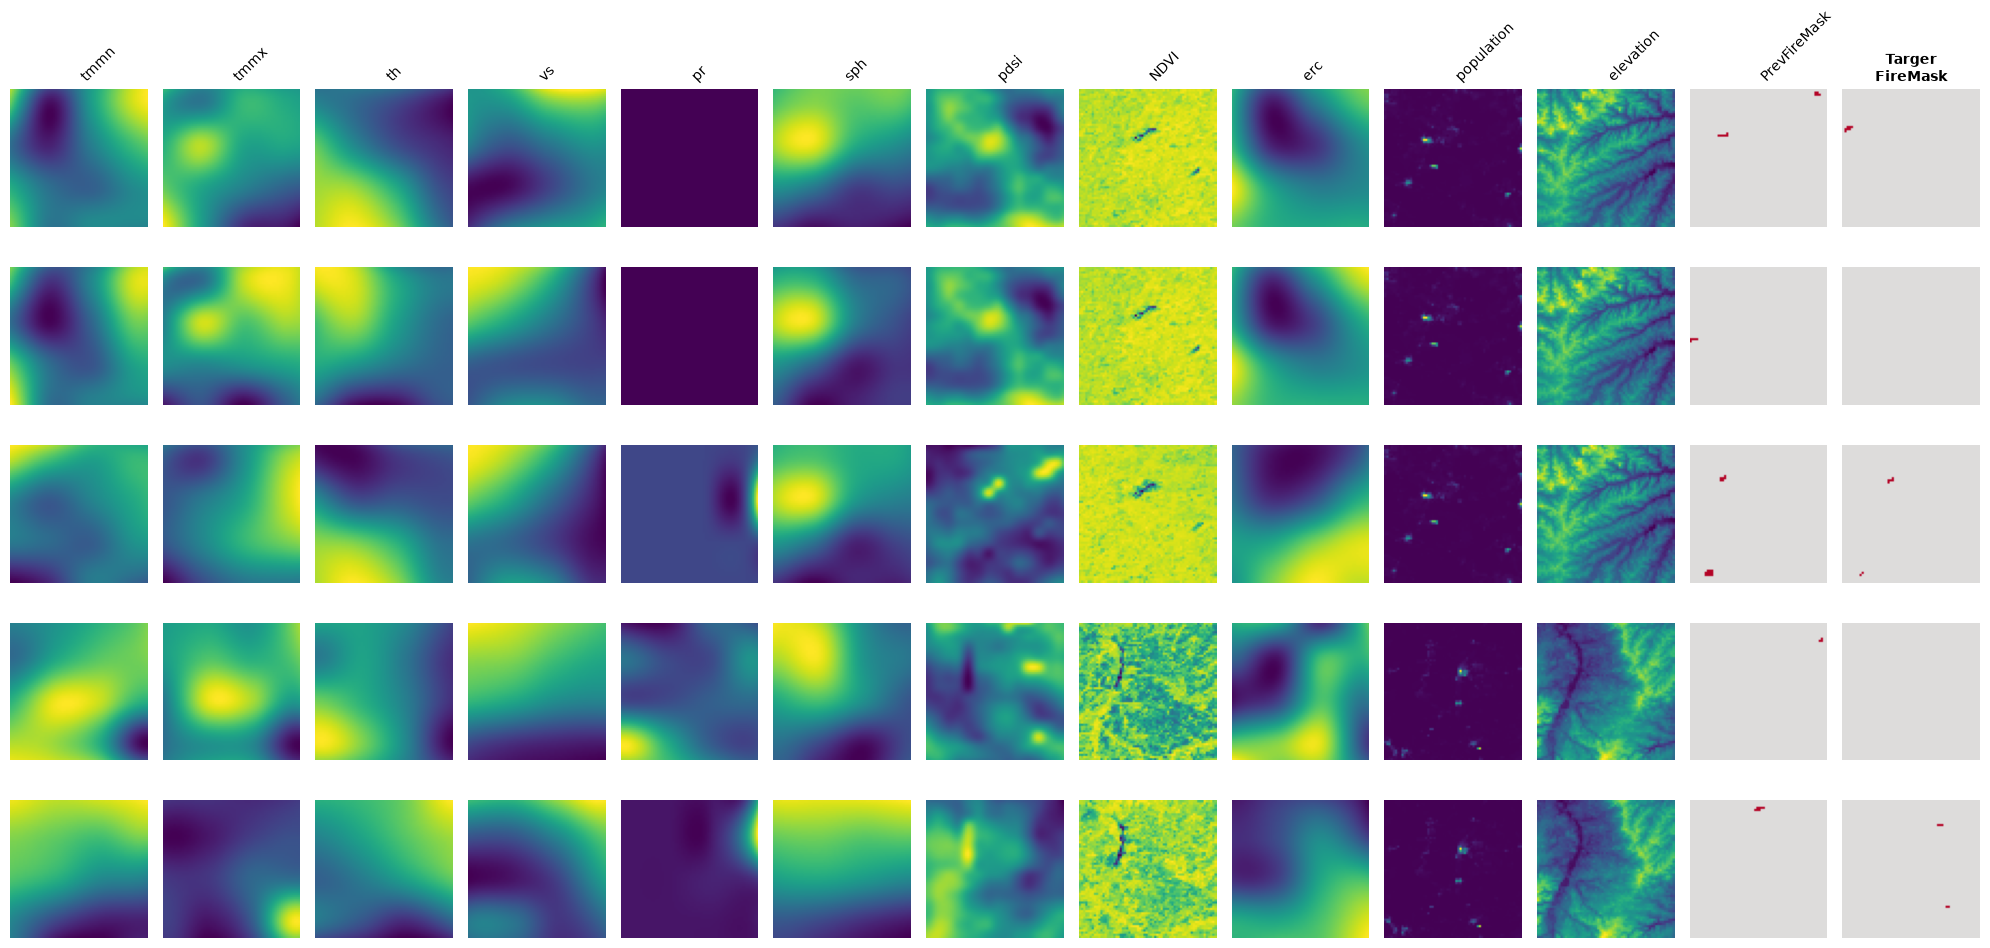

In [63]:
n_samples = 5
n_features = len(INPUT_FEATURES)

fig, axs = plt.subplots(nrows=n_samples, ncols=n_features + 1, figsize=(20,10))

for i in range(n_samples):
    for j, feature_name in enumerate(INPUT_FEATURES):
        ax = axs[i,j]
        pixel_grid = X_train[i, :, :, j]

        if feature_name in ['PrevFireMask', 'FireMask']:
            im = ax.imshow(pixel_grid, cmap='coolwarm', vmin=-1, vmax=1)
        else:
            im = ax.imshow(pixel_grid, cmap='viridis')
        ax.axis('off')

        if i == 0:
            ax.set_title(feature_name, fontsize=10, rotation=45, ha='left')

    ax_target = axs[i, -1]
    target_grid = Y_train[i, :, :]

    ax_target.imshow(target_grid, cmap='coolwarm', vmin=-1, vmax=1)
    ax_target.axis('off')

    if i == 0:
        ax_target.set_title('Targer\nFireMask', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

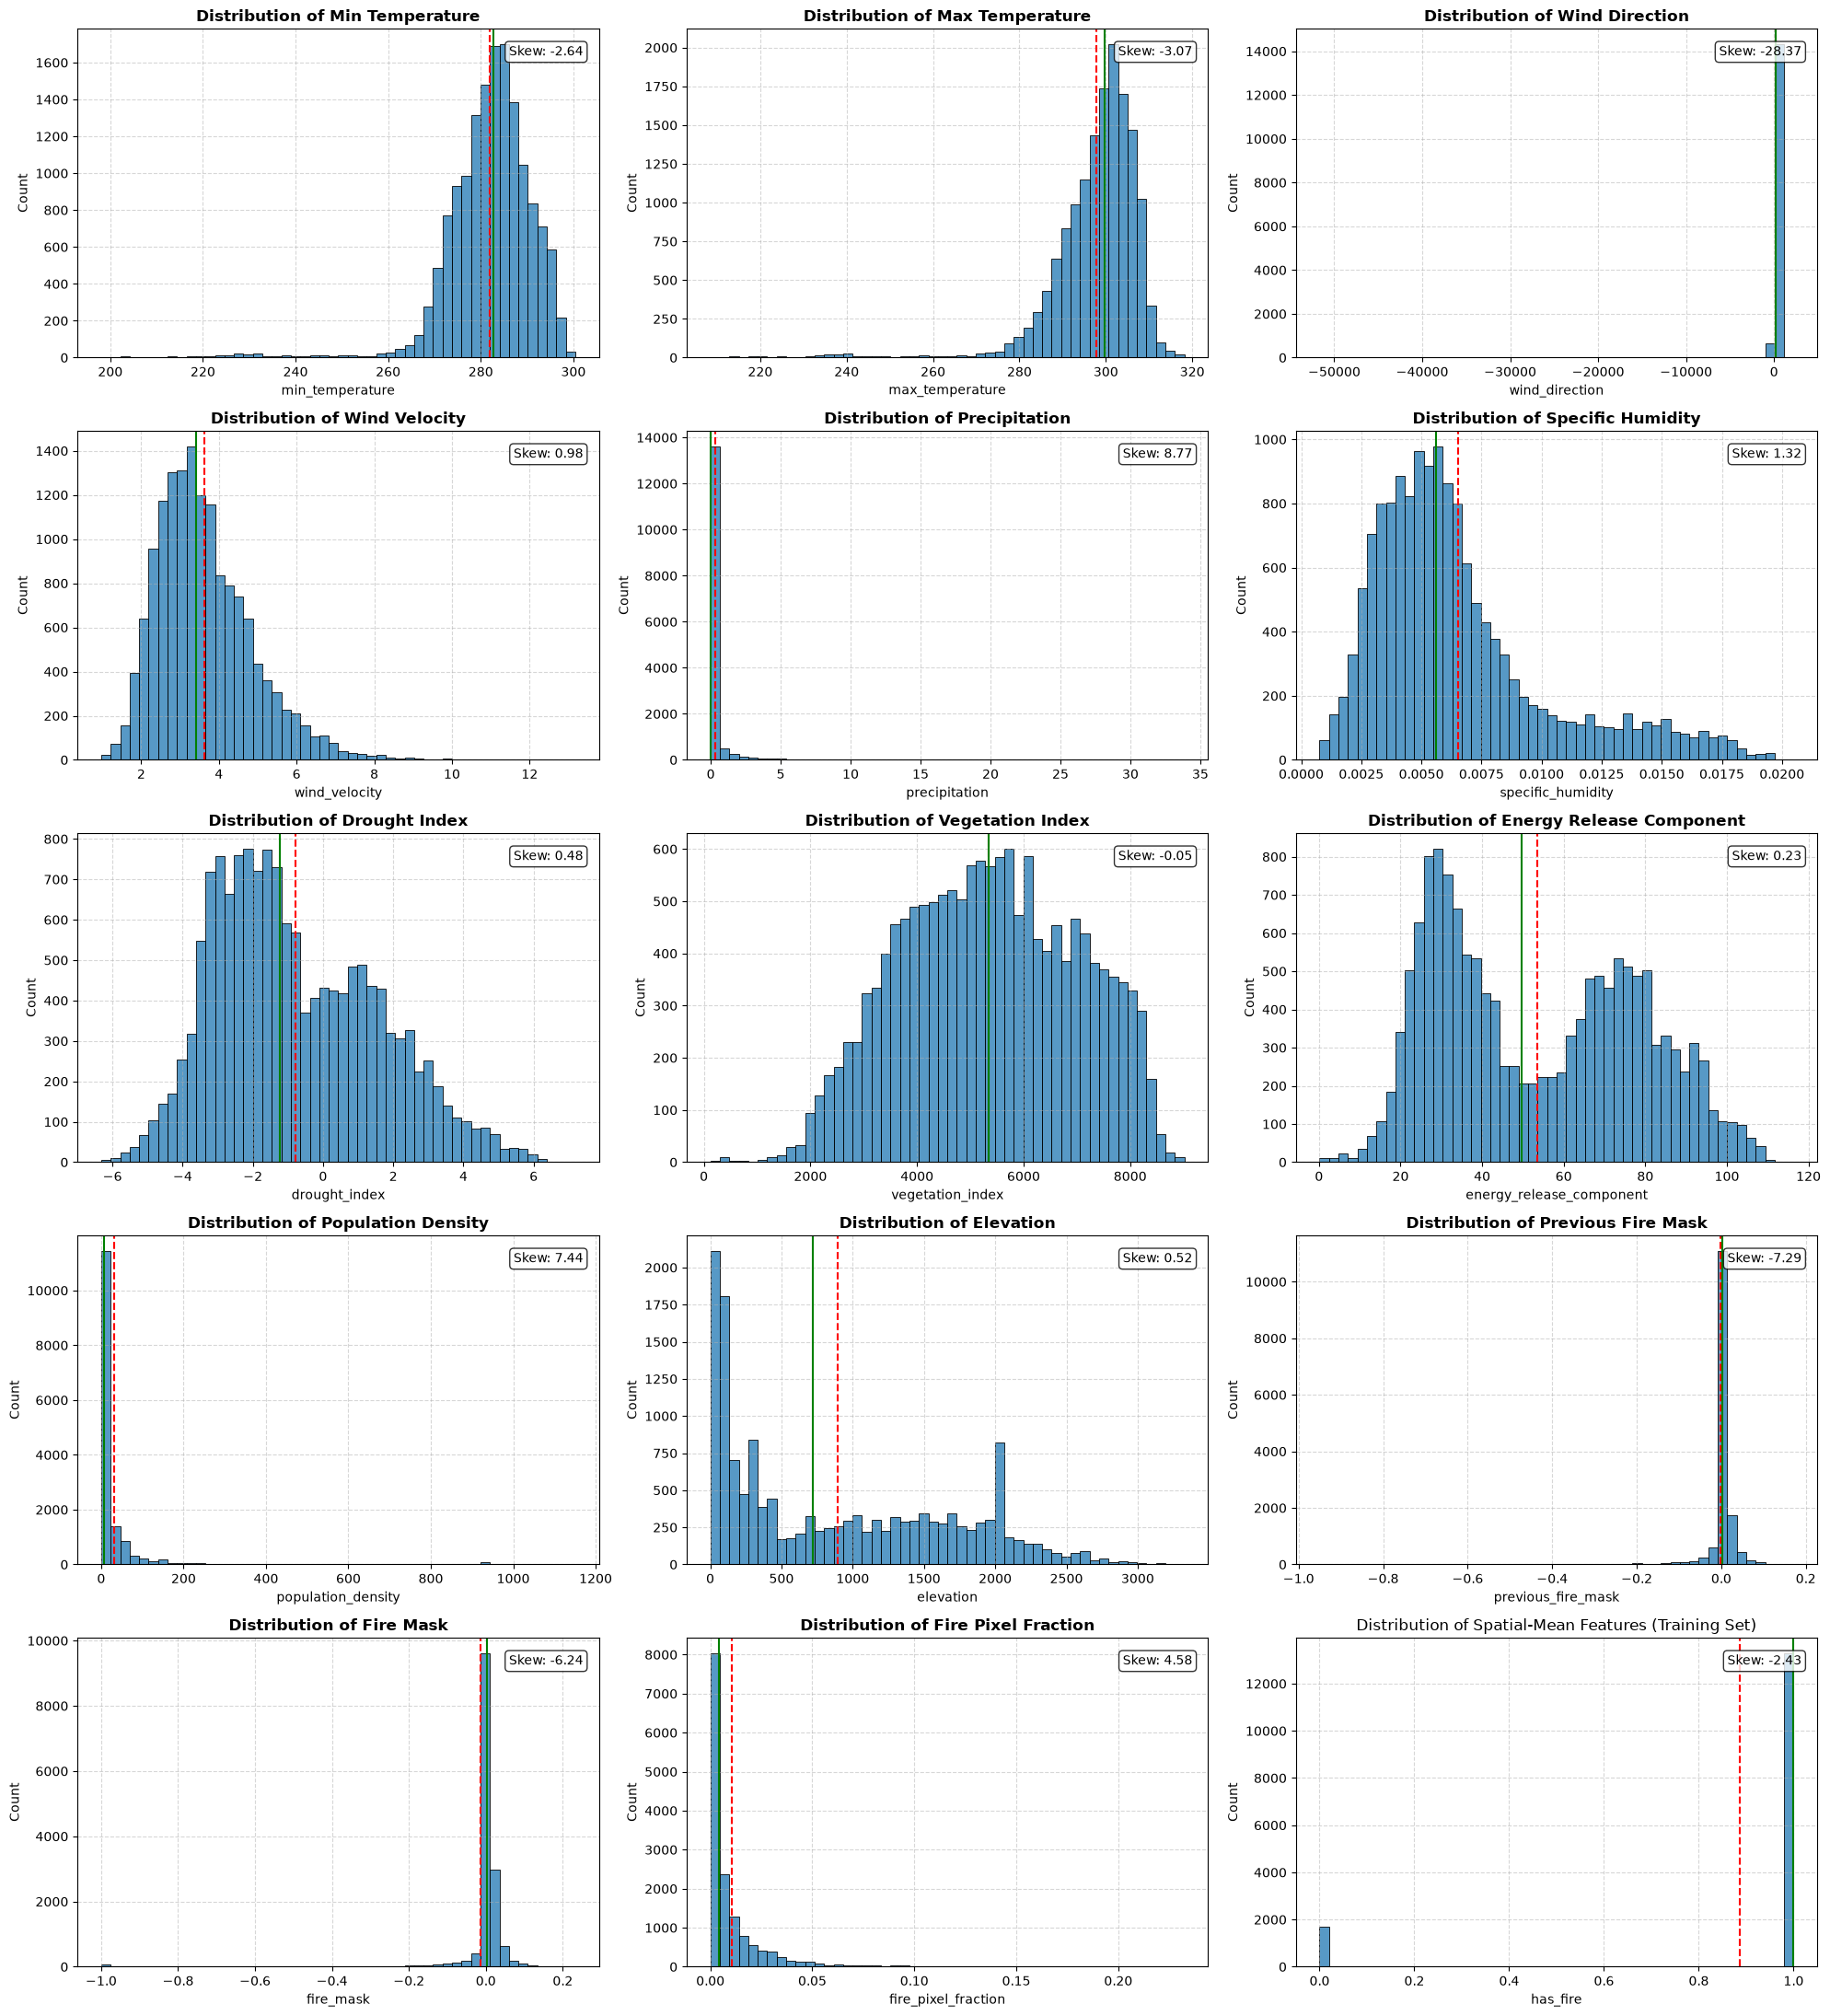

In [64]:
fig, axs = plt.subplots(nrows=5, ncols=3, figsize=(20,22))
axs = axs.flatten()

for i, col_name in enumerate(df_train.columns):
    data = df_train[col_name].dropna()
    mean, median, skew = data.mean(), data.median(), data.skew()

    sns.histplot(data = df_train, x = col_name, bins = 50, kde = False, ax = axs[i])

    axs[i].axvline(mean, color='red', linestyle='--', linewidth=1.5, label=f'Mean: {mean:.2f}')
    axs[i].axvline(median, color='green', linestyle='-', linewidth=1.5, label=f'Median: {median:.2f}')

    axs[i].text(0.97, 0.95, f'Skew: {skew:.2f}', transform=axs[i].transAxes,
                ha='right', va='top', fontsize=10,
                bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))


    axs[i].set_title(f'Distribution of {col_name.replace('_', ' ').title()}', fontsize=12, fontweight='bold')
    axs[i].set_xlabel(col_name)
    axs[i].set_ylabel('Count')
    axs[i].grid(True, linestyle= '--', alpha = 0.5)

if len(axs) > len(df_train.columns):
    for j in range(len(df_train.columns), len(axs)):
        axs[j].axis('off')

plt.title('Distribution of Spatial-Mean Features (Training Set)')
plt.tight_layout()
plt.show()
    

In [65]:
for col in df_train.columns:
  print(f'Column: {col}')
  print(f'Minimum value: {df_train[col].min()}')
  print(f'Maximum value: {df_train[col].max()}')
  print(df_train[col].quantile([0.25, 0.5, 0.75]))


  #notice wind direction, precipitation, drought index have sus values

Column: min_temperature
Minimum value: 198.03306579589844
Maximum value: 300.3972473144531
0.25    277.414215
0.50    282.819427
0.75    287.588135
Name: min_temperature, dtype: float64
Column: max_temperature
Minimum value: 208.4518280029297
Maximum value: 318.1873779296875
0.25    293.603897
0.50    299.709564
0.75    303.928116
Name: max_temperature, dtype: float64
Column: wind_direction
Minimum value: -51674.703125
Maximum value: 2226.989501953125
0.25    152.115555
0.50    207.459244
0.75    252.161552
Name: wind_direction, dtype: float64
Column: wind_velocity
Minimum value: 0.9697684645652771
Maximum value: 13.17342472076416
0.25    2.747284
0.50    3.419904
0.75    4.327089
Name: wind_velocity, dtype: float64
Column: precipitation
Minimum value: -0.028327757492661476
Maximum value: 33.865478515625
0.25    0.000000
0.50    0.000000
0.75    0.021898
Name: precipitation, dtype: float64
Column: specific_humidity
Minimum value: 0.0007627710583619773
Maximum value: 0.02048580348491668

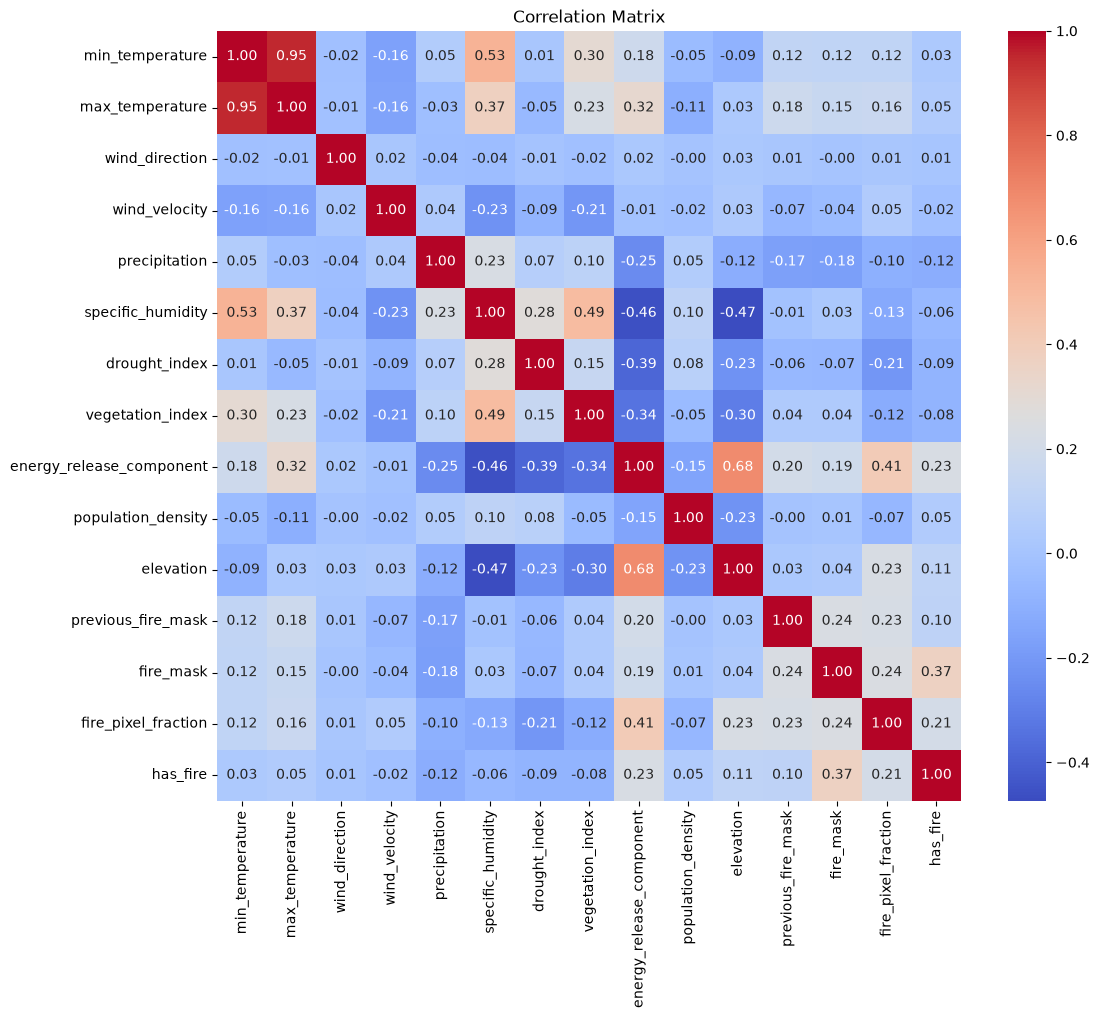

In [66]:
plt.figure(figsize=(12, 10))
corr_matrix = df_train.corr(method = 'pearson')
sns.heatmap(corr_matrix, annot = True, cmap = 'coolwarm', fmt = '.2f')
plt.title('Correlation Matrix')
plt.show()

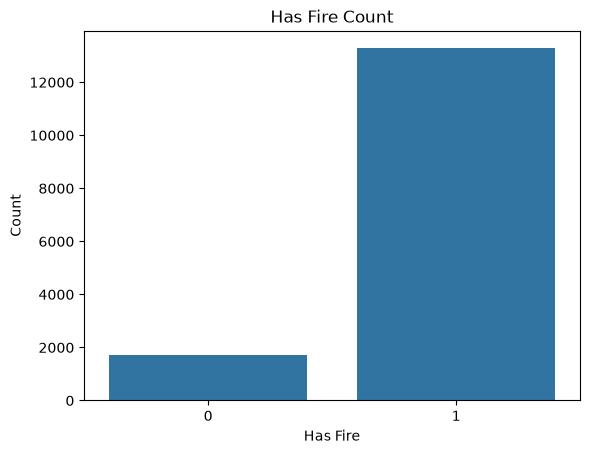

In [67]:
sns.countplot(data = df_train, x = 'has_fire')
plt.title('Has Fire Count')
plt.xlabel('Has Fire')
plt.ylabel('Count')
plt.show()

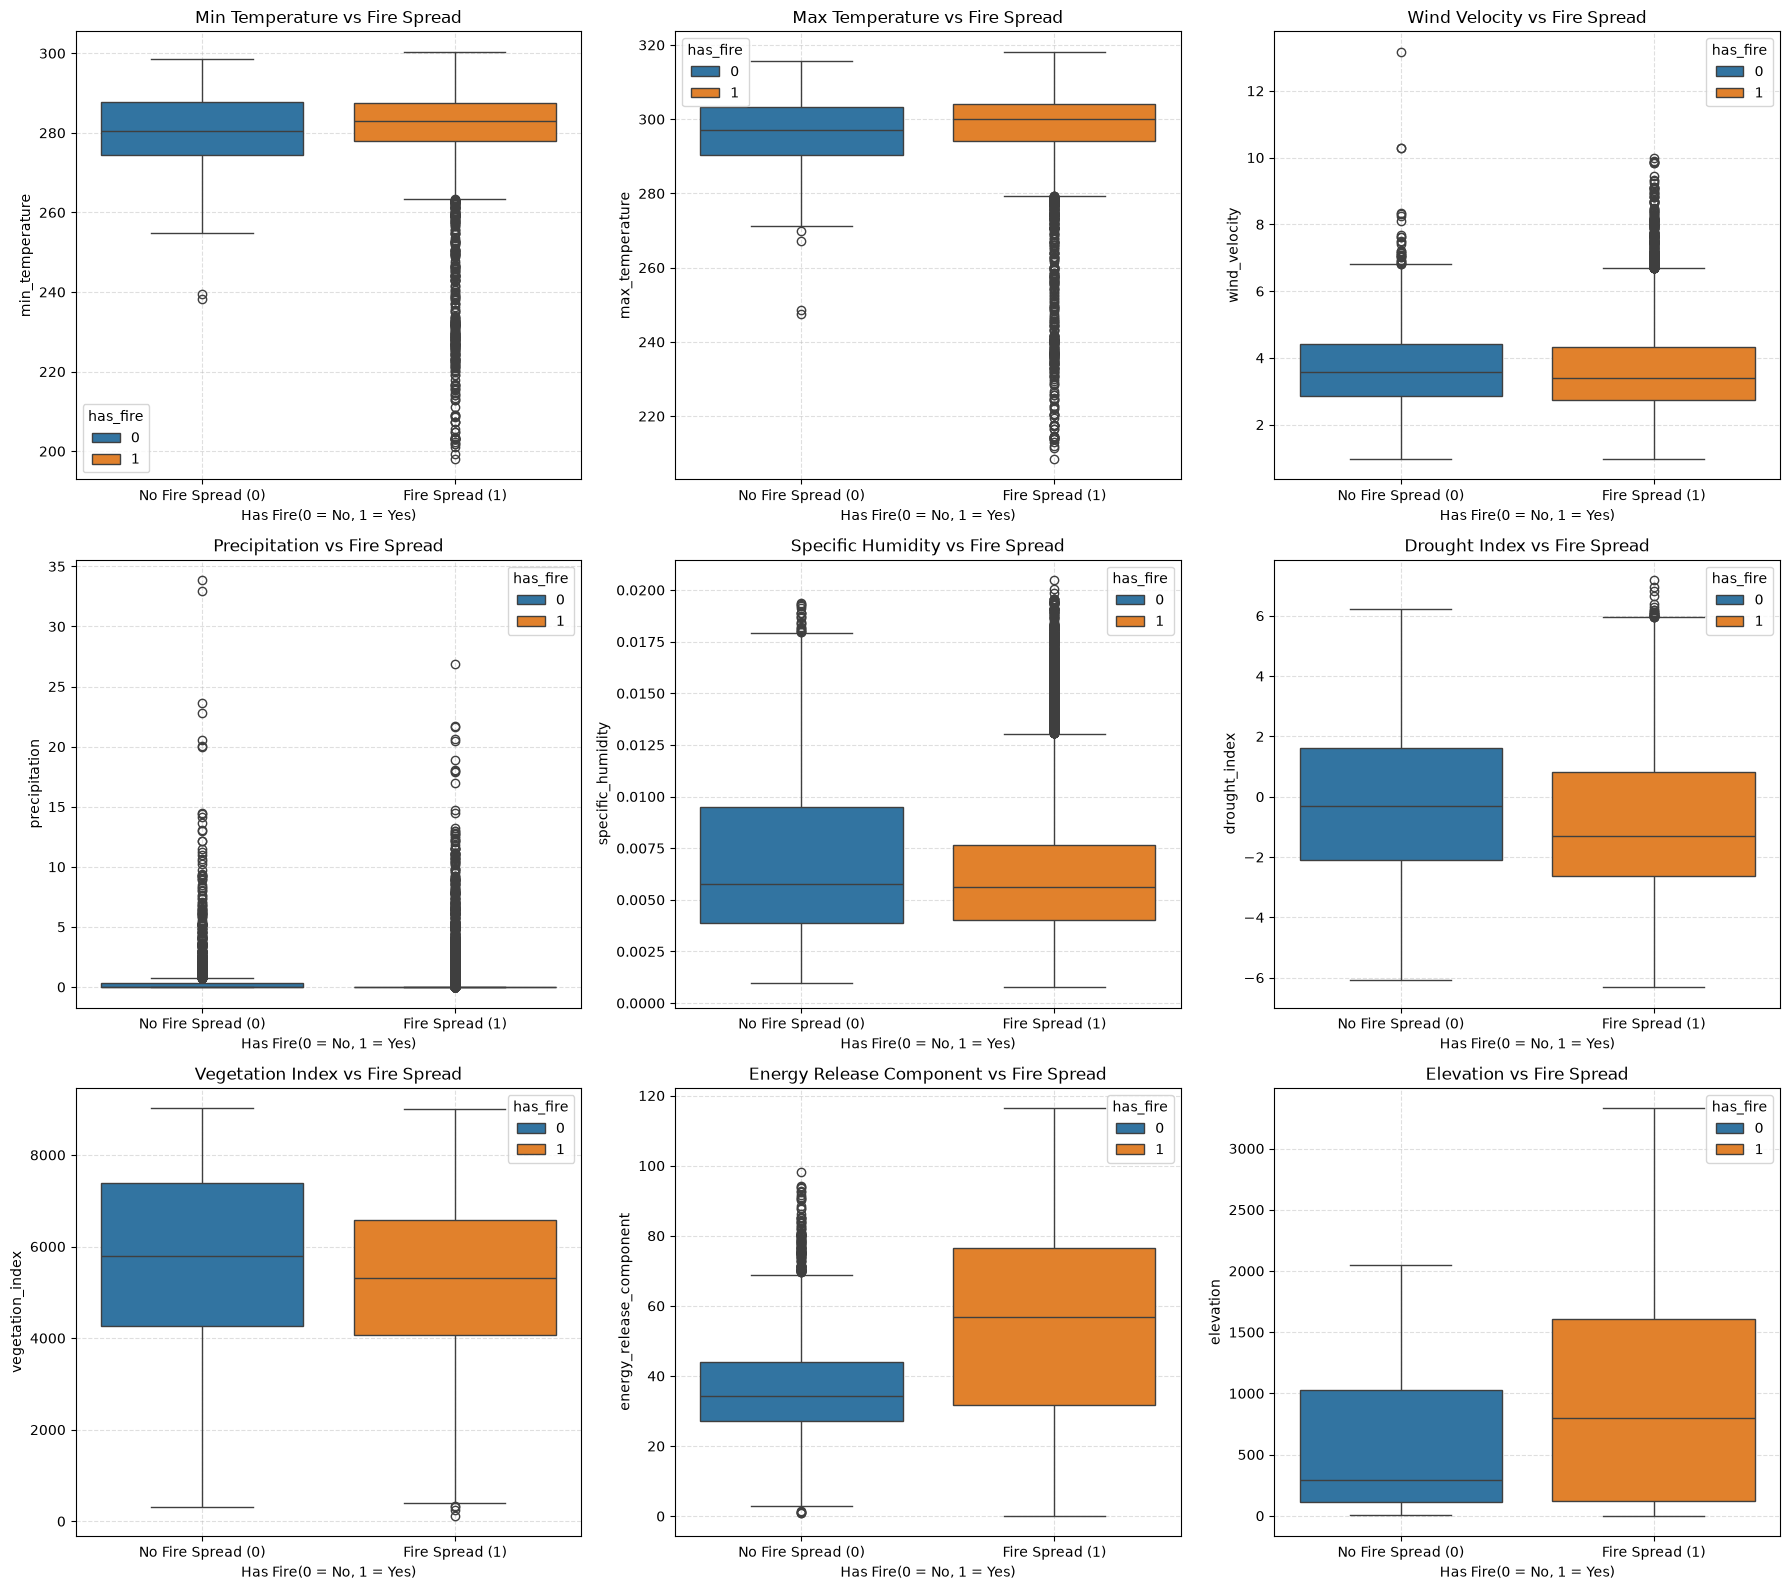

In [68]:
features_to_compare = [
    'min_temperature', 'max_temperature', 'wind_velocity',
    'precipitation', 'specific_humidity', 'drought_index',
    'vegetation_index', 'energy_release_component', 'elevation'
]
fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(18,16))
axs = axs.flatten()

for i, feature in enumerate(features_to_compare):
  sns.boxplot(data = df_train, x='has_fire', y=feature, ax=axs[i], hue='has_fire')

  title_name = feature.replace('_', ' ').title()
  axs[i].set_title(f'{title_name} vs Fire Spread')
  axs[i].set_xlabel('Has Fire(0 = No, 1 = Yes)')
  axs[i].set_ylabel(feature)

  axs[i].set_xticks([0, 1])
  axs[i].set_xticklabels(['No Fire Spread (0)', 'Fire Spread (1)'])

  axs[i].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


Plotting: largest fire (#11326, frac=0.2324), medium fire (#252, frac=0.0051), no fire (#1, frac=0.0000)


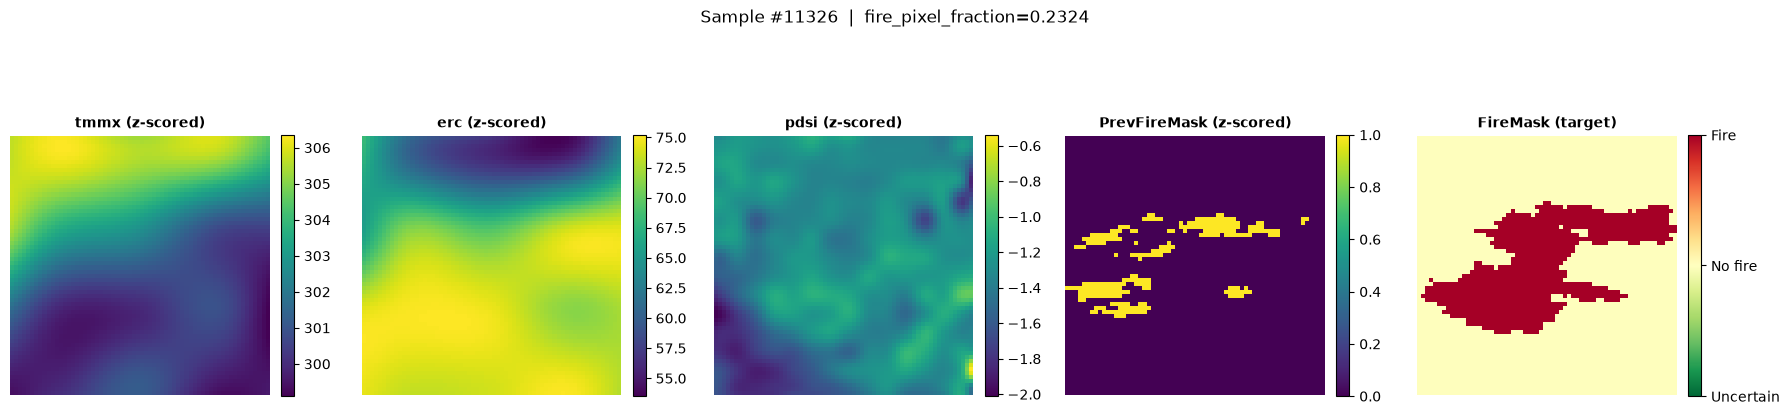

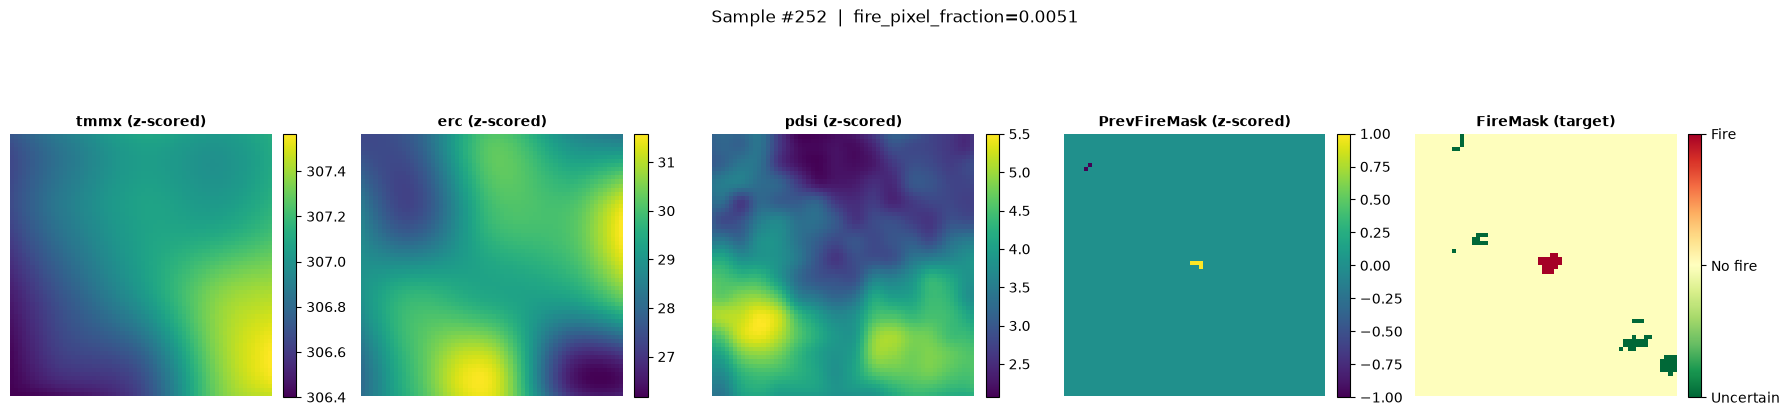

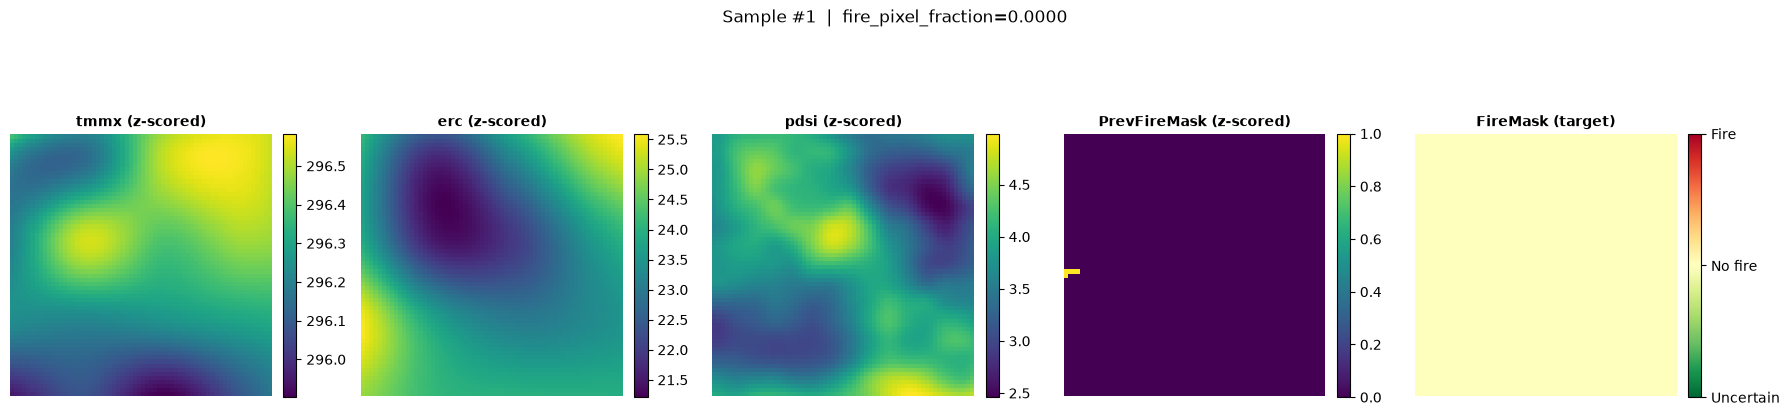

In [69]:
def plot_fire_scene(idx, show_features=('tmmx', 'erc', 'pdsi', 'PrevFireMask'), figsize=(18, 5)):
    ch_idx = [INPUT_FEATURES.index(f) for f in show_features]
    fig, axes = plt.subplots(1, len(show_features) + 1, figsize=figsize)

    for j, (feat, ci) in enumerate(zip(show_features, ch_idx)):
        ax = axes[j]
        im = ax.imshow(X_train[idx, :, :, ci], cmap='viridis')
        plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        ax.set_title(f'{feat} (z-scored)', fontweight='bold', fontsize=10)
        ax.axis('off')

    ax = axes[-1]
    im = ax.imshow(Y_train[idx], cmap='RdYlGn_r', vmin=-1, vmax=1)
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, ticks=[-1, 0, 1])
    cbar.ax.set_yticklabels(['Uncertain', 'No fire', 'Fire'])
    ax.set_title('FireMask (target)', fontweight='bold', fontsize=10)
    ax.axis('off')

    fig.suptitle(
        f'Sample #{idx}  |  fire_pixel_fraction={df_train.loc[idx, "fire_pixel_fraction"]:.4f}',
        fontsize=12
    )
    plt.tight_layout()
    plt.show()


# Three illustrative samples: large fire, a medium-sized fire, and a no-fire scene
frac = df_train['fire_pixel_fraction'].values

large_idx   = int(np.nanargmax(frac))
fire_idxs   = np.where(frac > 0)[0]
median_idx  = fire_idxs[int(np.argmin(np.abs(frac[fire_idxs] - np.nanmedian(frac[fire_idxs]))))]
no_fire_idx = int(np.where(frac == 0)[0][0])

print(f'Plotting: largest fire (#{large_idx}, frac={frac[large_idx]:.4f}), '
      f'medium fire (#{median_idx}, frac={frac[median_idx]:.4f}), '
      f'no fire (#{no_fire_idx}, frac={frac[no_fire_idx]:.4f})')

for idx in [large_idx, median_idx, no_fire_idx]:
    plot_fire_scene(idx)

### Preprocessing for EDA

In [70]:
df_train['precipitation'] = df_train['precipitation'].clip(lower=0)
df_train['vegetation_index'] = df_train['vegetation_index'].clip(lower=0)

#wind
valid_median = df_train.loc[(df_train['wind_direction'] >= 0) & (df_train['wind_direction'] <= 360),'wind_direction']
wind_median = valid_median.median()
df_train['wind_direction'] = df_train['wind_direction'].apply(lambda x: x if 0 <= x <= 360 else wind_median)

#temps
temp_median = df_train.loc[df_train['min_temperature'] > 240, 'min_temperature'].median()
df_train['min_temperature'] = df_train['min_temperature'].apply(lambda x: x if x>240 else temp_median)

#returning to true scale
df_train['vegetation_index'] = df_train['vegetation_index']/10000

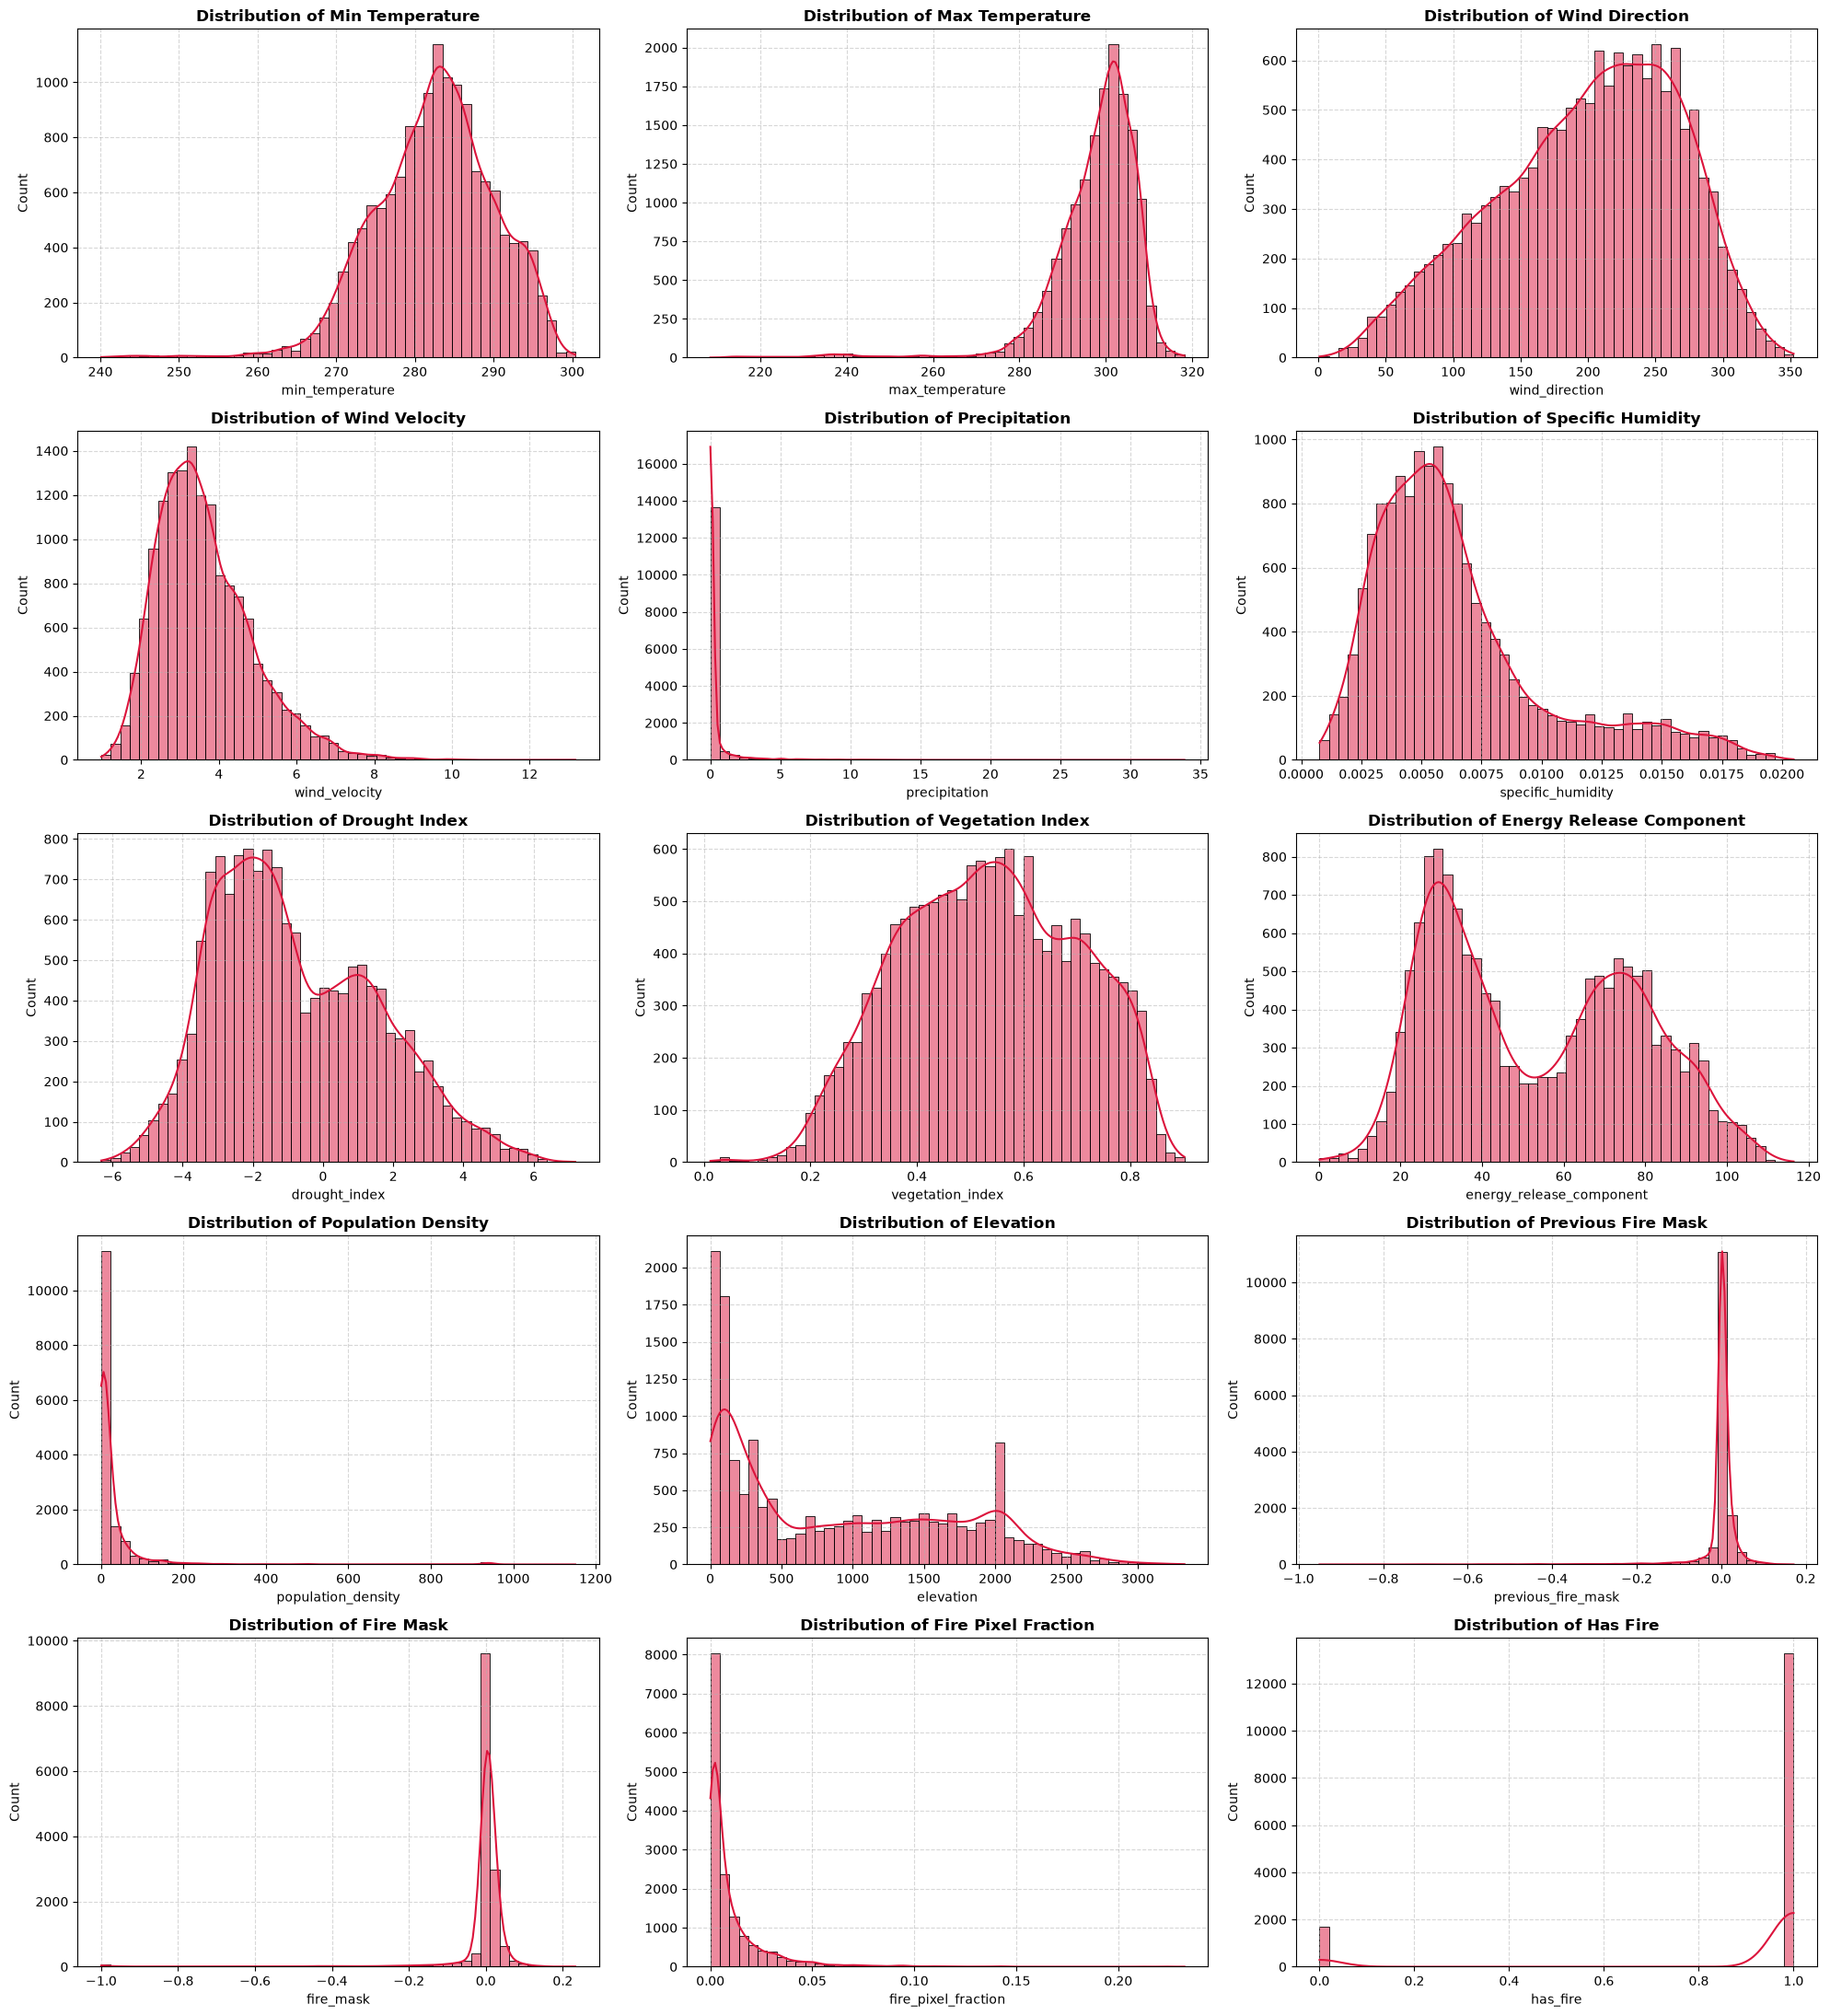

In [71]:
# Replotting distributions after preprocessing
fig, axs = plt.subplots(nrows=5, ncols=3, figsize=(20, 22))
axs = axs.flatten()  # Flatten the 2D grid array into a 1D list for easy looping


for i, col_name in enumerate(df_train.columns):
    sns.histplot(data=df_train, x=col_name, bins=50, kde=True, ax=axs[i], color='crimson')

    axs[i].set_title(f'Distribution of {col_name.replace("_", " ").title()}', fontsize=12, fontweight='bold')
    axs[i].set_xlabel(col_name)
    axs[i].set_ylabel('Count')
    axs[i].grid(True, linestyle='--', alpha=0.5)

if len(axs) > len(df_train.columns):
    for j in range(len(df_train.columns), len(axs)):
        axs[j].axis('off')

plt.tight_layout()
plt.show()

In [72]:
for col in df_train.columns:
  print(f'Column: {col}')
  print(f'Minimum value: {df_train[col].min()}')
  print(f'Maximum value: {df_train[col].max()}')
  print(df_train[col].quantile([0.25, 0.5, 0.75]));

Column: min_temperature
Minimum value: 240.1046600341797
Maximum value: 300.3972473144531
0.25    277.756546
0.50    282.902893
0.75    287.588135
Name: min_temperature, dtype: float64
Column: max_temperature
Minimum value: 208.4518280029297
Maximum value: 318.1873779296875
0.25    293.603897
0.50    299.709564
0.75    303.928116
Name: max_temperature, dtype: float64
Column: wind_direction
Minimum value: 0.9059313535690308
Maximum value: 352.474853515625
0.25    152.559395
0.50    207.473557
0.75    251.823524
Name: wind_direction, dtype: float64
Column: wind_velocity
Minimum value: 0.9697684645652771
Maximum value: 13.17342472076416
0.25    2.747284
0.50    3.419904
0.75    4.327089
Name: wind_velocity, dtype: float64
Column: precipitation
Minimum value: 0.0
Maximum value: 33.865478515625
0.25    0.000000
0.50    0.000000
0.75    0.021898
Name: precipitation, dtype: float64
Column: specific_humidity
Minimum value: 0.0007627710583619773
Maximum value: 0.020485803484916687
0.25    0.004

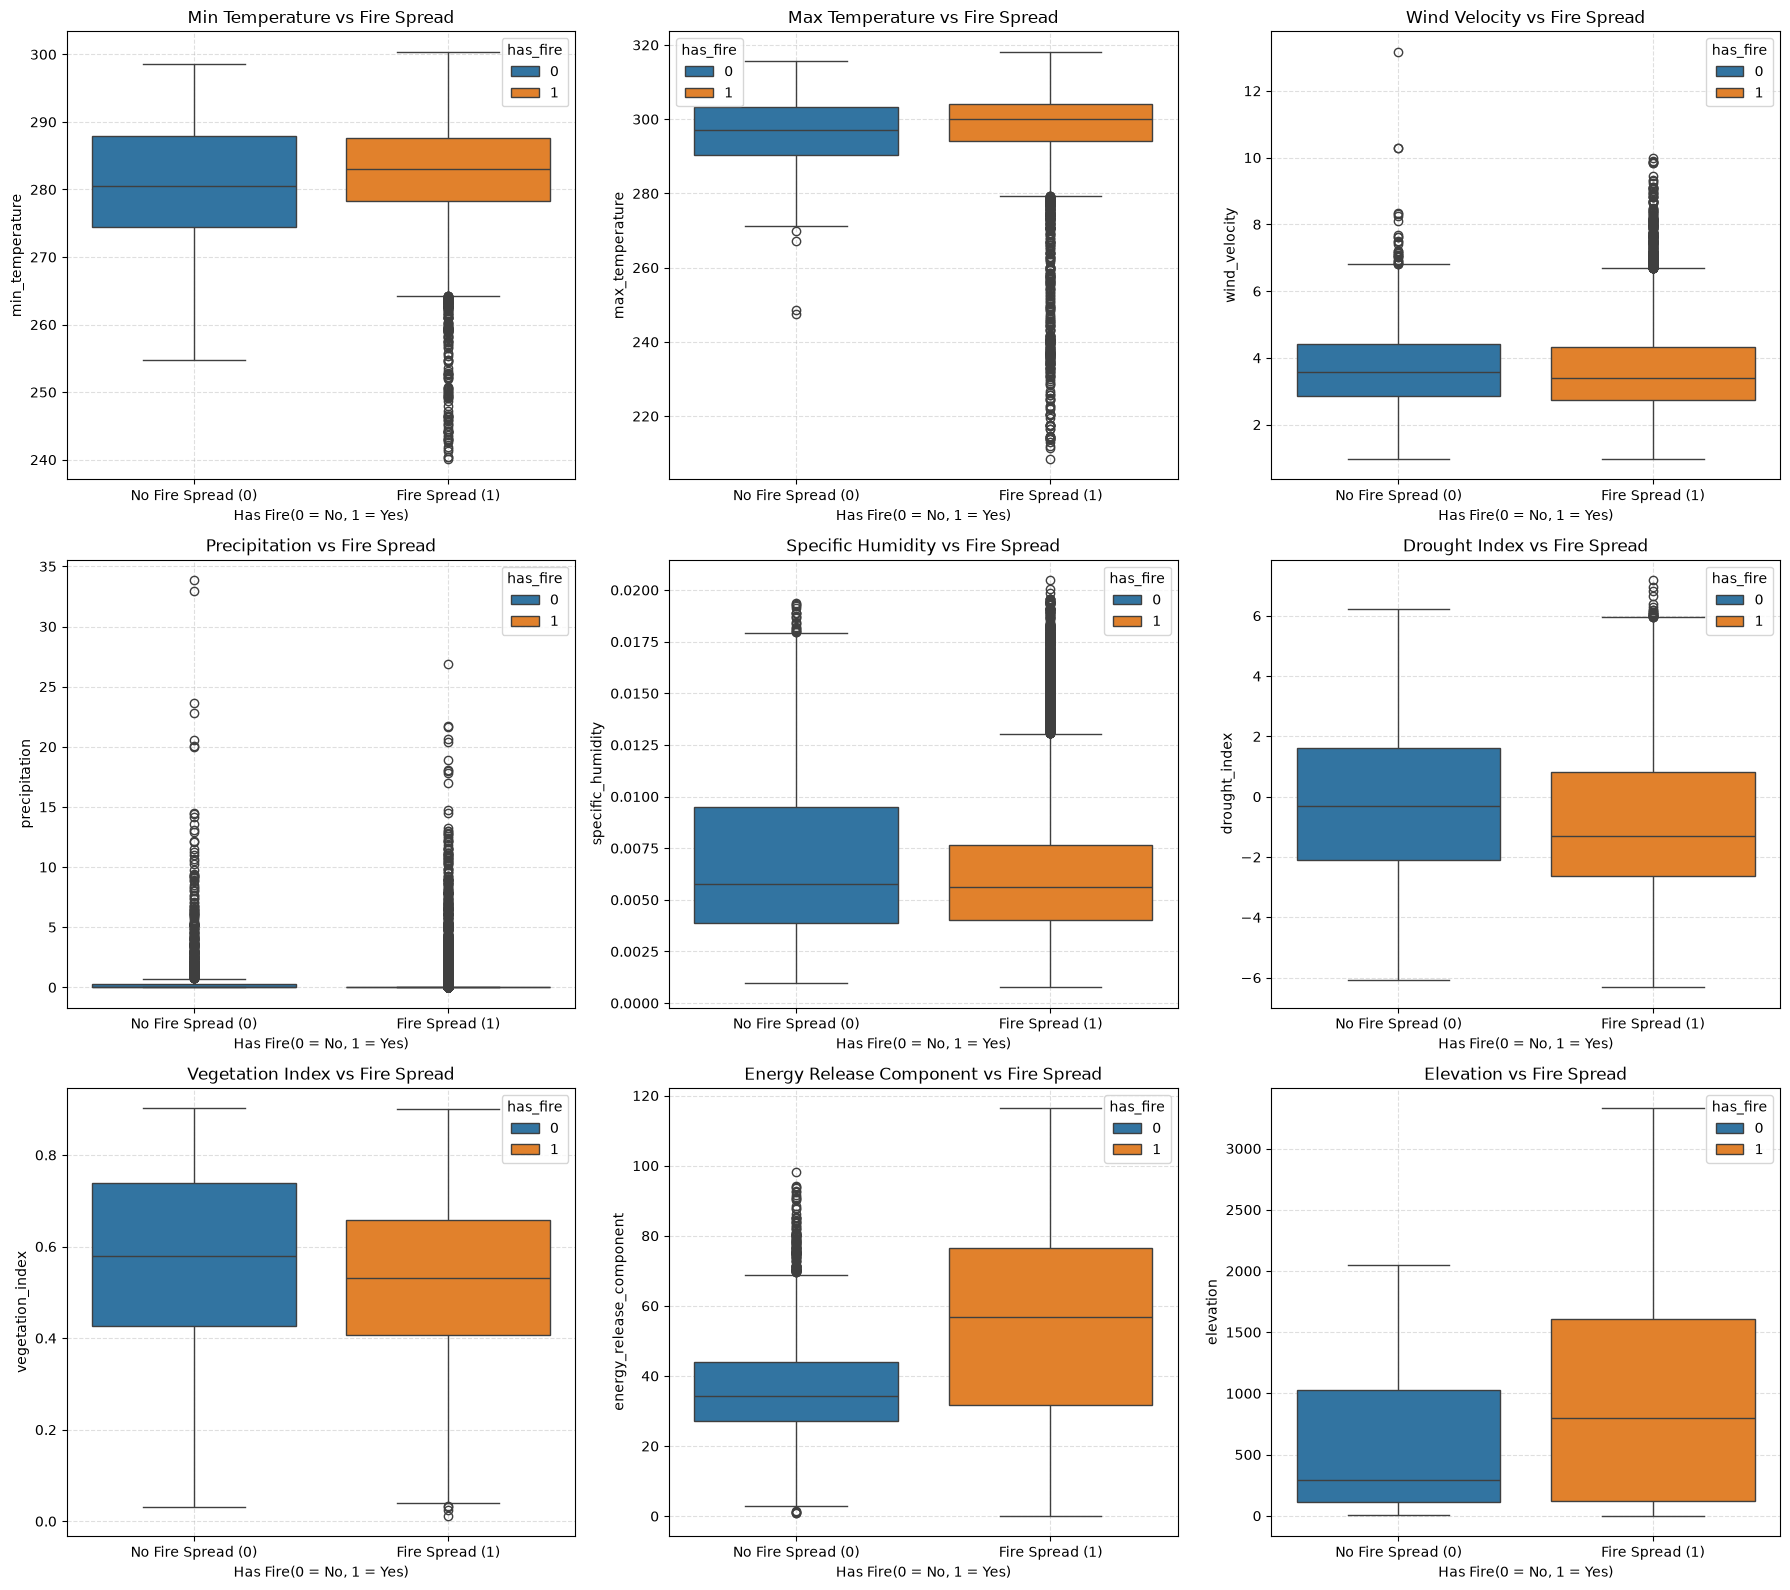

In [73]:
features_to_compare = [
    'min_temperature', 'max_temperature', 'wind_velocity',
    'precipitation', 'specific_humidity', 'drought_index',
    'vegetation_index', 'energy_release_component', 'elevation'
]
fig, axs = plt.subplots(nrows=3, ncols=3, figsize=(18,16))
axs = axs.flatten()

for i, feature in enumerate(features_to_compare):
  sns.boxplot(data = df_train, x='has_fire', y=feature, ax=axs[i], hue='has_fire')

  title_name = feature.replace('_', ' ').title()
  axs[i].set_title(f'{title_name} vs Fire Spread')
  axs[i].set_xlabel('Has Fire(0 = No, 1 = Yes)')
  axs[i].set_ylabel(feature)

  axs[i].set_xticks([0, 1])
  axs[i].set_xticklabels(['No Fire Spread (0)', 'Fire Spread (1)'])

  axs[i].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


# Preprocessing for Modeling (Tensor-level cleaning)

#### Setup

In [74]:
IDX = {name: i for i, name in enumerate(INPUT_FEATURES)}

BOUNDS = {
    'tmmn':       (240, 320),        # K (-33 °C to 47 °C)
    'tmmx':       (240, 330),        # K, world record high ≈ 329.8 K
    'th':         (0, 360),          # degrees
    'vs':         (0, 15),           # m/s; values above were isolated 1-pixel spikes
    'pr':         (0, None),         # mm; None = no upper limit
    'sph':        (0, 0.03),         # kg/kg; humidity can't be negative
    'pdsi':       (-10, 10),
    'NDVI':       (-10000, 10000),   # stored as NDVI × 10,000
    'erc':        (0, 120),          # values above were isolated 1-pixel spikes
    'population': (0, None),
    'elevation':  (-100, 4500),      # m; Death Valley ≈ -86 m
}

NO_DATA_FEATURES = ['tmmn', 'tmmx', 'th', 'vs', 'sph', 'erc']

def range_report(X):
    for feat, (lo, hi) in BOUNDS.items():
        vals = X[..., IDX[feat]]
        below = (vals < lo).sum() if lo is not None else 0
        above = (vals > hi).sum() if hi is not None else 0
        print(f"{feat:11s} min={vals.min():>12.3f}  max={vals.max():>12.3f}  "
              f"below={below:>9,}  above={above:>9,}")

#### Checks before cleaning

In [75]:
#overall range check
assert not data_cleaned, "Data is already cleaned. Re-run the loading cell first."

range_report(X_train)

# Sample-level view: would dropping bad samples lose a lot of data?
lo, hi = BOUNDS['th']
bad_wd = (X_train[..., IDX['th']] < lo) | (X_train[..., IDX['th']] > hi)
bad_tmin = X_train[..., IDX['tmmn']] < BOUNDS['tmmn'][0]
print(f"\nSamples with >=1 bad wind-direction pixel: {bad_wd.any(axis=(1, 2)).sum():,} / {len(X_train):,}")
print(f"Samples with >=1 bad min-temp pixel:       {bad_tmin.any(axis=(1, 2)).sum():,} / {len(X_train):,}")

tmmn        min=    -444.693  max=     716.628  below=  223,338  above=       37
tmmx        min=       0.000  max=    1229.849  below=  223,327  above=       78
th          min= -505870.062  max=   37735.629  below=   58,212  above=   82,132
vs          min=     -82.653  max=     103.220  below=      178  above=      189
pr          min=    -167.448  max=      56.215  below=5,998,537  above=        0
sph         min=      -0.129  max=       0.086  below=      154  above=       38
pdsi        min=    -125.711  max=      52.269  below=      141  above=      229
NDVI        min=   -9567.000  max=    9966.000  below=        0  above=        0
erc         min=   -1196.089  max=    2470.882  below=   17,582  above=      142
population  min=       0.000  max=   27103.605  below=        0  above=        0
elevation   min=     -45.000  max=    4193.000  below=        0  above=        0

Samples with >=1 bad wind-direction pixel: 360 / 14,979
Samples with >=1 bad min-temp pixel:       515 / 14,

In [76]:
#fire masks
prev = X_train[..., IDX['PrevFireMask']]
fire = Y_train
print("PrevFireMask unique values (sample):", np.unique(prev)[:10])
print("FireMask unique values (sample):", np.unique(fire)[:10])
print("PrevFireMask == -1 count:", (prev == -1).sum(), f"({100*(prev==-1).mean():.3f}%)")
print("FireMask == -1 count:", (fire == -1).sum(), f"({100*(fire==-1).mean():.3f}%)")

PrevFireMask unique values (sample): [-1.  0.  1.]
FireMask unique values (sample): [-1.  0.  1.]
PrevFireMask == -1 count: 670613 (1.093%)
FireMask == -1 count: 1440911 (2.349%)


In [77]:
#no data fire masks
IDX = {name: i for i, name in enumerate(INPUT_FEATURES)}
no_data_features = ['tmmn', 'tmmx', 'th', 'vs', 'sph', 'erc']

# Step 1: for each feature, find where it's exactly 0.0
zero_masks = {}
for feat in no_data_features:
    vals = X_train[..., IDX[feat]]
    zero_masks[feat] = (vals == 0.0)
    print(f"{feat}: {zero_masks[feat].sum():,} zero pixels ({100*zero_masks[feat].mean():.3f}%)")

# Step 2: check whether these masks line up at the SAME pixel positions across all six
combined_mask = zero_masks[no_data_features[0]].copy()
for feat in no_data_features[1:]:
    combined_mask &= zero_masks[feat]

print(f"\nPixels where ALL SIX features are simultaneously 0.0: {combined_mask.sum():,}")

# Step 3: sanity check -- do individual masks match the intersection almost exactly?
# (if yes, it confirms one shared 'no data' pattern rather than six independent zero-readings)
for feat in no_data_features:
    overlap = (zero_masks[feat] & combined_mask).sum()
    only_this_feature = (zero_masks[feat] & ~combined_mask).sum()
    print(f"{feat}: {overlap:,} pixels overlap with shared mask, {only_this_feature:,} zero pixels NOT in shared mask")

tmmn: 223,309 zero pixels (0.364%)
tmmx: 223,309 zero pixels (0.364%)
th: 223,309 zero pixels (0.364%)
vs: 223,309 zero pixels (0.364%)
sph: 223,309 zero pixels (0.364%)
erc: 223,645 zero pixels (0.365%)

Pixels where ALL SIX features are simultaneously 0.0: 223,309
tmmn: 223,309 pixels overlap with shared mask, 0 zero pixels NOT in shared mask
tmmx: 223,309 pixels overlap with shared mask, 0 zero pixels NOT in shared mask
th: 223,309 pixels overlap with shared mask, 0 zero pixels NOT in shared mask
vs: 223,309 pixels overlap with shared mask, 0 zero pixels NOT in shared mask
sph: 223,309 pixels overlap with shared mask, 0 zero pixels NOT in shared mask
erc: 223,309 pixels overlap with shared mask, 336 zero pixels NOT in shared mask


In [78]:
#temp cutoffs
tmin = X_train[..., IDX['tmmn']]
# Look at values just above and just below your 240K cutoff
near_cutoff = tmin[(tmin > 200) & (tmin < 260)]
print("Count of values between 200K and 260K:", near_cutoff.size)
for p in [1, 5, 25, 50, 75, 95, 99]:
    print(f"  p{p}: {np.percentile(near_cutoff, p):.1f} K  ({np.percentile(near_cutoff, p) - 273.15:.1f} °C)")

print("\nHow many values are between 240K and 250K (i.e. cold but plausible, right above your cutoff)?")
print(((tmin > 240) & (tmin < 250)).sum())


Count of values between 200K and 260K: 70522
  p1: 253.7 K  (-19.5 °C)
  p5: 256.0 K  (-17.2 °C)
  p25: 257.9 K  (-15.2 °C)
  p50: 258.6 K  (-14.5 °C)
  p75: 259.4 K  (-13.8 °C)
  p95: 259.9 K  (-13.3 °C)
  p99: 260.0 K  (-13.2 °C)

How many values are between 240K and 250K (i.e. cold but plausible, right above your cutoff)?
19


In [79]:
tmin_upper = X_train[..., IDX['tmmn']] 
print("Values above 320K (about 47°C, a generous upper bound for min-temp):", (tmin_upper > 320).sum())

near_upper = tmin_upper[(tmin_upper > 280) & (tmin_upper < 340)]
print("Count near upper boundary (280-340K):", near_upper.size)
for p in [50, 75, 90, 95, 99, 99.9, 100]:
    print(f"  p{p}: {np.percentile(near_upper, p):.1f} K")

Values above 320K (about 47°C, a generous upper bound for min-temp): 37
Count near upper boundary (280-340K): 40432552
  p50: 286.2 K
  p75: 290.3 K
  p90: 294.0 K
  p95: 295.4 K
  p99: 297.5 K
  p99.9: 300.0 K
  p100: 331.6 K


In [80]:
#near-zero negatives

pr_vals = X_train[..., IDX['pr']]
neg_pr = pr_vals[pr_vals < 0]
print("Negative pr percentiles:")
for p in [1, 5, 25, 50, 75, 95, 99, 100]:
    print(f"  p{p}: {np.percentile(neg_pr, p):.3f}")

print("negatives between -1 and 0:", ((pr_vals < 0) & (pr_vals > -1)).sum())
print("negatives below -1:        ", (pr_vals <= -1).sum())


Negative pr percentiles:
  p1: -0.132
  p5: -0.041
  p25: -0.009
  p50: -0.003
  p75: -0.000
  p95: -0.000
  p99: -0.000
  p100: -0.000
negatives between -1 and 0: 5997466
negatives below -1:         1071


In [81]:
erc_vals = X_train[..., IDX['erc']]
neg_erc = erc_vals[erc_vals < 0]
print("Negative erc percentiles:")
for p in [1, 5, 25, 50, 75, 95, 99, 100]:
    print(f"  p{p}: {np.percentile(neg_erc, p):.3f}")

print("negatives between -1 and 0:", ((erc_vals < 0) & (erc_vals > -1)).sum())
print("negatives below -1:        ", (erc_vals <= -1).sum())

Negative erc percentiles:
  p1: -24.377
  p5: -0.767
  p25: -0.292
  p50: -0.099
  p75: -0.019
  p95: -0.001
  p99: -0.000
  p100: -0.000
negatives between -1 and 0: 16965
negatives below -1:         617


In [82]:
#spike checks
for feat, cutoff in [('tmmx', 325), ('vs', 15), ('erc', 120)]:
    vals = X_train[..., IDX[feat]]
    hi = BOUNDS[feat][1]
    print(f"{feat}: between {cutoff} and {hi}: {((vals > cutoff) & (vals <= hi)).sum():,}   above {hi}: {(vals > hi).sum():,}")

tmmx: between 325 and 330: 10   above 330: 78
vs: between 15 and 15: 0   above 15: 189
erc: between 120 and 120: 0   above 120: 142


In [83]:
erc = X_train[..., IDX['erc']]
extra = (erc == 0) & ~combined_mask      
samples = np.where(extra.any(axis=(1, 2)))[0]
print(f"{extra.sum()} pixels across {len(samples)} samples")
for s in samples[:10]:
    tile = erc[s]
    print(s, "zeros:", extra[s].sum(), " tile median:", np.median(tile[tile != 0]).round(1))

336 pixels across 2 samples
4464 zeros: 168  tile median: 0.0
11362 zeros: 168  tile median: 0.0


### Preprocessing Decisions

All decisions are based on the training set. Fill values are learned from the training set only and then applied unchanged wo validation and test sets, so no information leaks from val/test into training. 

#### Guiding Principles
- Impute, don't drop: A CNN needs a complete 64x64 sample, so a bad pixel can't be removed without removing the whole sample. Bad pixels are rare and scattered: only 360 / 14,979 samples contain any bad wind-direction pixel, and most of those samples are otherwise clean. Dropping them would throw away good data to remove a few bad pixels. 
- Clip small overshoots, impute impossible values: A value just past a physical  bound (ex: -0.003 mm of precipitation) still carries value; the true value was likely about zero, so it is clipped to the bound. A value far outside of anything physically possible (ex: wind direction of -505,870°) carries no information about the true value, so clipping it would invent an extreme reading (any bad value would become wind from due north or south). These values are treated as missing and imputed with the median of the training set. 
- Labels are left untouched:-1 in FireMask and PrevFireMask means "unlabeled", not an error. These pixels are excluded from the loss with a mask. 

#### Shared no-data mask: 
223,309 pixels (0.36%) are exactly 0 across six features (tmmn, tmmx, th, vs, sph, erc) in the same locations. This pattern likely means "no data" rather than six simultaneous true zeros, so these pixels are treated as missing in all six affected features. 

erc has an additional 336 zeros outside this mask, all in 2 samples whose other erc values are also around 0. This is consistent with very wet fuels, so these pixels are kept as real values. 

#### Bounds per feature:
    'tmmn':       (240, 320)        K (-33 °C to 47 °C)
    'tmmx':       (240, 330)        K, world record high ≈ 329.8 K
    'th':         (0, 360)          degrees
    'vs':         (0, 15)           m/s
    'pr':         (0, None)         mm; None = no upper limit
    'sph':        (0, 0.03)         kg/kg; humidity can't be negative
    'pdsi':       (-10, 10)    
    'NDVI':       (-10000, 10000)   stored as NDVI × 10,000
    'erc':        (0, 120)          
    'population': (0, None)
    'elevation':  (-100, 4500)      m; Death Valley ≈ -86 m


#### Transformations
- NDVI ÷ 10,000 to restore to true scale (-1,1)
- log1p on pr and population: both features are extremenly right-skewed; without transformation extreme values would compress everything else after standardization
- Standardized every input except PrevFireMask using training set mean and std


### Preprocessing

In [84]:
NO_DATA_FEATURES = ['tmmn', 'tmmx', 'th', 'vs', 'sph', 'erc']

def clean_tensor(X, fill_values=None):
    fit = fill_values is None          # fit=True only for the training set

    # ---- Phase 1: flag bad values as NaN ----
    no_data = (X[..., IDX['tmmn']] == 0)
    for feat in ['tmmx', 'th', 'vs', 'sph']:
        no_data &= (X[..., IDX[feat]] == 0)

    pr = X[..., IDX['pr']]
    pr[(pr < 0) & (pr > -1)] = 0       # rounding noise -> real zero, not missing

    erc = X[..., IDX['erc']]
    erc[(erc < 0) & (erc > -1)] = 0     # near-zero noise -> real zero
    for feat, (lo, hi) in BOUNDS.items():
        ch = X[..., IDX[feat]]         # a VIEW: changing ch changes X
        bad = np.zeros(ch.shape, dtype=bool)
        if lo is not None: bad |= ch < lo
        if hi is not None: bad |= ch > hi
        if feat in NO_DATA_FEATURES:
            bad |= no_data
        ch[bad] = np.nan

    # ---- Phase 2: compute fill values (train only), then fill ----
    if fit:
        fill_values = {f: float(np.nanmedian(X[..., IDX[f]])) for f in BOUNDS}
    for feat in BOUNDS:
        ch = X[..., IDX[feat]]
        ch[np.isnan(ch)] = fill_values[feat]

    return fill_values

data_cleaned = True
fill_values = clean_tensor(X_train)
clean_tensor(X_val,  fill_values)
clean_tensor(X_test, fill_values)

{'tmmn': 283.11138916015625,
 'tmmx': 299.8535461425781,
 'th': 208.28921508789062,
 'vs': 3.4322915077209473,
 'pr': 0.0,
 'sph': 0.005624198820441961,
 'pdsi': -1.3553898334503174,
 'NDVI': 5520.0,
 'erc': 49.717552185058594,
 'population': 0.1656579077243805,
 'elevation': 611.0}

In [85]:
#checks after cleaning
# 1. No NaNs left in any split
for name, X in [('train', X_train), ('val', X_val), ('test', X_test)]:
    print(f"{name}: NaNs remaining = {np.isnan(X).sum()}")

# 2. Every feature inside its bounds
#    (NDVI was divided by 10,000 at the end of clean_tensor, so its
#     bounds are now -1 to 1 instead of -10,000 to 10,000)
print("\nOut-of-bounds pixels after cleaning (train):")
for feat, (lo, hi) in BOUNDS.items():
    vals = X_train[..., IDX[feat]]
    if feat == 'NDVI':
        lo, hi = lo / 10000, hi / 10000
    below = (vals < lo).sum() if lo is not None else 0
    above = (vals > hi).sum() if hi is not None else 0
    print(f"  {feat:11s} min={vals.min():>10.3f}  max={vals.max():>10.3f}  below={below}  above={above}")

# 3. Fill value for wind direction
print(f"\nth fill value: {fill_values['th']:.1f}°  (should be ~208, not 147)")

# 4. Labels untouched
print("\nPrevFireMask values:", np.unique(X_train[..., IDX['PrevFireMask']]))
print("Y_train values:      ", np.unique(Y_train))

train: NaNs remaining = 0
val: NaNs remaining = 0
test: NaNs remaining = 0

Out-of-bounds pixels after cleaning (train):
  tmmn        min=   241.443  max=   319.957  below=0  above=0
  tmmx        min=   244.808  max=   329.993  below=0  above=0
  th          min=     0.000  max=   360.000  below=0  above=0
  vs          min=     0.006  max=    14.917  below=0  above=0
  pr          min=     0.000  max=    56.215  below=0  above=0
  sph         min=     0.000  max=     0.029  below=0  above=0
  pdsi        min=    -9.992  max=     9.995  below=0  above=0
  NDVI        min= -9567.000  max=  9966.000  below=570316  above=60298336
  erc         min=     0.000  max=   118.505  below=0  above=0
  population  min=     0.000  max= 27103.605  below=0  above=0
  elevation   min=   -45.000  max=  4193.000  below=0  above=0

th fill value: 208.3°  (should be ~208, not 147)

PrevFireMask values: [-1.  0.  1.]
Y_train values:       [-1.  0.  1.]


In [86]:
# Transformations
def transform_tensor(X):
    X[..., IDX['NDVI']] /= 10000.0
    for feat in ['pr', 'population']:
        X[..., IDX[feat]] = np.log1p(X[..., IDX[feat]])

assert data_cleaned and not data_transformed, "Run clean_tensor first, and transform only once"
for X in (X_train, X_val, X_test):
    transform_tensor(X)
data_transformed = True


In [87]:
assert data_transformed and not data_scaled, "Run the transform first, and scale only once."

def fit_scaler_streaming(X, scale_idx, chunk_size=500):
    # running totals, so the full array is never copied
    total_sum = np.zeros(len(scale_idx), dtype=np.float64)
    total_sq_sum = np.zeros(len(scale_idx), dtype=np.float64)
    total_count = 0
    for start in range(0, X.shape[0], chunk_size):
        chunk = X[start:start + chunk_size][..., scale_idx].reshape(-1, len(scale_idx)).astype(np.float64)
        total_sum += chunk.sum(axis=0)
        total_sq_sum += (chunk ** 2).sum(axis=0)
        total_count += chunk.shape[0]
    mean = total_sum / total_count
    std = np.sqrt(total_sq_sum / total_count - mean ** 2)   # std = sqrt(E[x²] - E[x]²)
    return mean, std

def scale_inplace(X, mean, std, scale_idx, chunk_size=500):
    for start in range(0, X.shape[0], chunk_size):
        end = start + chunk_size
        X[start:end, ..., scale_idx] = (X[start:end][..., scale_idx] - mean) / std

scale_channels = [f for f in INPUT_FEATURES if f != 'PrevFireMask']
scale_idx = [IDX[f] for f in scale_channels]

mean, std = fit_scaler_streaming(X_train, scale_idx)       # learned from train only
for X in (X_train, X_val, X_test):
    scale_inplace(X, mean, std, scale_idx)                 # same numbers applied to all three
data_scaled = True
gc.collect();

In [89]:
#checks after transformations

pd.set_option('display.max_rows', None)
#what the scaler learned
scaler = pd.DataFrame({'mean': mean, 'std': std}, index = scale_channels)
print(scaler.round(4))
print(f"th std: {std[scale_channels.index('th')]:.1f}")

#scaled distributions for each split
rows = []
for split, X in [('train', X_train), ('val', X_val), ('test', X_test)]:
    for f in scale_channels:
        v = X[..., IDX[f]]
        rows.append({'split': split, 'feature': f, 
                     'mean': v.mean(dtype=np.float64), 'std': v.std(dtype = np.float64), 
                     'min': v.min(), 'max': v.max(), 
                     '%|z|>5': 100 * (np.abs(v) > 5).mean()})
summary = pd.DataFrame(rows)

print('Mean and std by split (train should be 0/1):')
print(summary.pivot(index='feature', columns='split', values=['mean', 'std']).round(3))

print('Train z-score range:')
print(summary[summary.split == 'train'].set_index('feature')[['min', 'max', '%|z|>5']].round(3))

#nothing broke
for split, X in [('train', X_train), ('val', X_val), ('test', X_test)]:
    print(f'{split}: all values finite = {np.isfinite(X).all()}')
print('PrevFireMask values:', np.unique(X_train[..., IDX['PrevFireMask']]))

                mean       std
tmmn        282.8826    7.2049
tmmx        298.8079    7.4028
th          200.1782   70.0518
vs            3.6403    1.2883
pr            0.1289    0.4010
sph           0.0065    0.0037
pdsi         -0.7729    2.4400
NDVI          0.5351    0.2185
erc          53.6508   24.8779
population    0.9657    1.4830
elevation   896.5713  842.6104
nth std: 70.1
Mean and std by split (train should be 0/1):
             mean                 std             
split        test train    val   test train    val
feature                                           
NDVI       -0.007   0.0 -0.234  0.972   1.0  1.008
elevation   0.074   0.0  0.028  1.019   1.0  1.026
erc         0.039   0.0  0.024  1.029   1.0  1.043
pdsi       -0.206   0.0  0.318  0.970   1.0  1.099
population -0.043   0.0 -0.045  0.957   1.0  0.974
pr          0.084   0.0 -0.004  1.144   1.0  1.018
sph        -0.083  -0.0 -0.083  0.935   1.0  0.910
th         -0.001  -0.0 -0.090  1.074   1.0  1.002
tmmn    

In [90]:
SAVE_PATH = '/Users/jordanagresti/Desktop/Data Projects/Wildfire/processed_jordan/'
os.makedirs(SAVE_PATH, exist_ok=True)

assert data_cleaned and data_transformed and data_scaled, "Run the full preprocessing first."

arrays = {'X_train': X_train, 'Y_train': Y_train,
          'X_val':   X_val,   'Y_val':   Y_val,
          'X_test':  X_test,  'Y_test':  Y_test}
for name, arr in arrays.items():
    np.save(os.path.join(SAVE_PATH, name + '.npy'), arr)
    print(f"Saved {name}: shape={arr.shape}, dtype={arr.dtype}")

# record the preprocessing settings alongside the data
import json
with open(os.path.join(SAVE_PATH, 'preprocessing_params.json'), 'w') as f:
    json.dump({'BOUNDS': BOUNDS, 'fill_values': fill_values,
               'scale_channels': scale_channels,
               'mean': mean.tolist(), 'std': std.tolist()}, f, indent=2)

Saved X_train: shape=(14979, 64, 64, 12), dtype=float32
Saved Y_train: shape=(14979, 64, 64), dtype=float32
Saved X_val: shape=(1877, 64, 64, 12), dtype=float32
Saved Y_val: shape=(1877, 64, 64), dtype=float32
Saved X_test: shape=(1689, 64, 64, 12), dtype=float32
Saved Y_test: shape=(1689, 64, 64), dtype=float32
